In [13]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd

PROJECT_ROOT = Path(
    "/Users/modjrin1/Library/CloudStorage/OneDrive-AaltoUniversity/"
    "paper 4 - mobility spain/heat-conditioned-accessibility"
)

RAW_GRAPH = PROJECT_ROOT / "data" / "raw" / "sevilla_walk.graphml"
UTCI_RASTER = PROJECT_ROOT / "outputs" / "solweig" / "summary" / "utci_max.tif"

G = ox.load_graphml(RAW_GRAPH)

nodes, edges = ox.graph_to_gdfs(G)

nodes = nodes.to_crs("EPSG:25830")
edges = edges.to_crs("EPSG:25830")

nodes["x"] = nodes.geometry.x
nodes["y"] = nodes.geometry.y

In [14]:
G = ox.load_graphml(THERMAL_GRAPH)

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("CRS:", G.graph["crs"])

Nodes: 1630
Edges: 4612
CRS: EPSG:25830


In [16]:
# Check that the thermal attributes survived GraphML saving/loading
sample_edge = next(iter(G.edges(keys=True, data=True)))

u, v, k, data = sample_edge

print("Sample edge:")
print("u:", u)
print("v:", v)
print("key:", k)

for field in [
    "length",
    "walk_time_s",
    "utci_max_mean",
    "heat_excess",
    "thermal_cost_s",
    "cost_ratio",
]:
    print(field, ":", data.get(field))

Sample edge:
u: 304499541
v: 1957097246
key: 0
length : 27.603267020271634
walk_time_s : 19.716619300194026
utci_max_mean : None
heat_excess : 9.960105895996094
thermal_cost_s : 29.535599637161834
cost_ratio : 1.4980052709579468


In [17]:
for u, v, k, data in G.edges(keys=True, data=True):
    for field in [
        "walk_time_s",
        "thermal_cost_s",
        "utci_max_mean",
        "cost_ratio"
    ]:
        if field in data:
            data[field] = float(data[field])

In [18]:
largest_component = max(
    nx.strongly_connected_components(G),
    key=len
)

G_main = G.subgraph(
    largest_component
).copy()

print("Connected nodes:", G_main.number_of_nodes())
print("Connected edges:", G_main.number_of_edges())

Connected nodes: 1565
Connected edges: 4494


In [19]:
def route_metric(G, route, attribute):
    total = 0.0

    for u, v in zip(route[:-1], route[1:]):
        parallel_edges = G[u][v]

        values = [
            float(data[attribute])
            for data in parallel_edges.values()
            if attribute in data
        ]

        if not values:
            return np.nan

        total += min(values)

    return total

In [20]:
def route_length(G, route):
    return route_metric(
        G,
        route,
        "length"
    )

In [21]:
def compare_routes(G, origin, destination):

    fastest = nx.shortest_path(
        G,
        origin,
        destination,
        weight="walk_time_s"
    )

    thermal = nx.shortest_path(
        G,
        origin,
        destination,
        weight="thermal_cost_s"
    )

    result = {
        "origin": origin,
        "destination": destination,

        "same_route": fastest == thermal,

        "fast_time_s":
            route_metric(G, fastest, "walk_time_s"),

        "thermal_route_time_s":
            route_metric(G, thermal, "walk_time_s"),

        "fast_route_thermal_cost":
            route_metric(G, fastest, "thermal_cost_s"),

        "thermal_route_thermal_cost":
            route_metric(G, thermal, "thermal_cost_s"),

        "fast_length_m":
            route_length(G, fastest),

        "thermal_length_m":
            route_length(G, thermal),
    }

    result["extra_time_s"] = (
        result["thermal_route_time_s"]
        - result["fast_time_s"]
    )

    result["thermal_cost_reduction"] = (
        result["fast_route_thermal_cost"]
        - result["thermal_route_thermal_cost"]
    )

    result["thermal_cost_reduction_pct"] = (
        100
        * result["thermal_cost_reduction"]
        / result["fast_route_thermal_cost"]
    )

    return result, fastest, thermal

In [22]:
rng = np.random.default_rng(42)

nodes = np.array(
    list(G_main.nodes)
)

N_PAIRS = 100

pairs = []

while len(pairs) < N_PAIRS:

    origin, destination = rng.choice(
        nodes,
        size=2,
        replace=False
    )

    if origin == destination:
        continue

    pairs.append(
        (origin, destination)
    )

In [23]:
results = []

for origin, destination in pairs:

    try:
        result, _, _ = compare_routes(
            G_main,
            origin,
            destination
        )

        results.append(result)

    except nx.NetworkXNoPath:
        continue

route_results = pd.DataFrame(results)

route_results.head()

,origin,destination,same_route,fast_time_s,thermal_route_time_s,fast_route_thermal_cost,thermal_route_thermal_cost,fast_length_m,thermal_length_m,extra_time_s,thermal_cost_reduction,thermal_cost_reduction_pct
0,427144273,12146727290,False,1292.502408,1294.259544,1906.178740,1897.592406,1809.503372,1811.963362,1.757136,8.586334,0.450447
1,10699214735,891138737,True,282.096198,282.096198,416.922409,416.922409,394.934677,394.934677,0.000000,0.000000,0.000000
2,12170640589,765623266,False,1141.748383,1143.052285,1690.442933,1687.929716,1598.447736,1600.273199,1.303902,2.513217,0.148672
3,405475397,746303070,True,1056.128904,1056.128904,1558.711622,1558.711622,1478.580466,1478.580466,0.000000,0.000000,0.000000
4,12705640688,1941502707,True,1132.038420,1132.038420,1637.494999,1637.494999,1584.853787,1584.853787,0.000000,0.000000,0.000000


In [24]:
route_results[
    [
        "same_route",
        "extra_time_s",
        "thermal_cost_reduction_pct"
    ]
].describe()

,extra_time_s,thermal_cost_reduction_pct
count,100.000000,87.000000
mean,8.640817,0.094600
std,42.055873,0.339028
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,0.623164,0.005119
max,265.655466,2.924275


In [25]:
changed_share = (
    (~route_results["same_route"]).mean()
    * 100
)

print(
    f"Thermal impedance changed the selected route "
    f"for {changed_share:.1f}% of sampled OD pairs."
)

Thermal impedance changed the selected route for 31.0% of sampled OD pairs.


In [26]:
changed = route_results[
    ~route_results["same_route"]
].copy()

changed = changed.sort_values(
    "thermal_cost_reduction_pct",
    ascending=False
)

changed.head(10)

,origin,destination,same_route,fast_time_s,thermal_route_time_s,fast_route_thermal_cost,thermal_route_thermal_cost,fast_length_m,thermal_length_m,extra_time_s,thermal_cost_reduction,thermal_cost_reduction_pct
53,13138176509,13140716034,False,230.270573,230.562010,342.072808,332.069656,322.378802,322.786814,0.291437,10.003151,2.924275
48,5729880240,13063176561,False,853.037138,853.660302,1270.696271,1262.453322,1194.251993,1195.124423,0.623164,8.242948,0.648695
45,4828484246,1367517630,False,1177.007930,1178.159413,1729.989506,1720.463938,1647.811102,1649.423179,1.151483,9.525568,0.550614
79,728689617,427144348,False,1138.213880,1138.837044,1691.487810,1683.244862,1593.499432,1594.371862,0.623164,8.242948,0.487319
65,494288795,308855459,False,1178.157234,1178.780398,1740.918644,1732.675696,1649.420128,1650.292558,0.623164,8.242948,0.473483
0,427144273,12146727290,False,1292.502408,1294.259544,1906.178740,1897.592406,1809.503372,1811.963362,1.757136,8.586334,0.450447
56,715559725,4943621739,False,1022.873860,1026.905816,1505.248664,1498.910550,1432.023404,1437.668143,4.031956,6.338114,0.421068
55,886460038,13031294063,False,1163.448173,1164.134061,1720.094284,1713.202678,1628.827443,1629.787685,0.685888,6.891606,0.400653
44,308855463,2039966045,False,1819.471201,1821.228336,2682.707150,2674.120816,2547.259681,2549.719671,1.757136,8.586334,0.320062
83,405611436,427123935,False,1445.364505,1450.375902,2131.304441,2125.443740,2023.510307,2030.526263,5.011397,5.860701,0.274982


In [27]:
example = changed.iloc[0]

origin = example["origin"]
destination = example["destination"]

comparison, fastest_route, thermal_route = compare_routes(
    G_main,
    origin,
    destination
)

pd.Series(comparison)

origin                        13138176509
destination                   13140716034
same_route                          False
fast_time_s                    230.270573
thermal_route_time_s            230.56201
fast_route_thermal_cost        342.072808
thermal_route_thermal_cost     332.069656
fast_length_m                  322.378802
thermal_length_m               322.786814
extra_time_s                     0.291437
thermal_cost_reduction          10.003151
thermal_cost_reduction_pct       2.924275
dtype: object

In [28]:
nodes_gdf, edges_gdf = ox.graph_to_gdfs(
    G_main
)

In [29]:
def route_to_gdf(G, route):

    records = []

    for u, v in zip(
        route[:-1],
        route[1:]
    ):

        edges = G[u][v]

        best_key = min(
            edges,
            key=lambda k:
                float(
                    edges[k]["walk_time_s"]
                )
        )

        record = edges[best_key].copy()

        if "geometry" not in record:
            from shapely.geometry import LineString

            record["geometry"] = LineString([
                (
                    G.nodes[u]["x"],
                    G.nodes[u]["y"]
                ),
                (
                    G.nodes[v]["x"],
                    G.nodes[v]["y"]
                )
            ])

        records.append(record)

    return gpd.GeoDataFrame(
        records,
        geometry="geometry",
        crs=G.graph["crs"]
    )

In [30]:
def weighted_route_to_gdf(
    G,
    route,
    weight
):

    records = []

    for u, v in zip(
        route[:-1],
        route[1:]
    ):

        edges = G[u][v]

        best_key = min(
            edges,
            key=lambda k:
                float(edges[k][weight])
        )

        record = edges[best_key].copy()

        if "geometry" not in record:
            from shapely.geometry import LineString

            record["geometry"] = LineString([
                (
                    G.nodes[u]["x"],
                    G.nodes[u]["y"]
                ),
                (
                    G.nodes[v]["x"],
                    G.nodes[v]["y"]
                )
            ])

        records.append(record)

    return gpd.GeoDataFrame(
        records,
        geometry="geometry",
        crs=G.graph["crs"]
    )

In [31]:
fast_gdf = weighted_route_to_gdf(
    G_main,
    fastest_route,
    "walk_time_s"
)

thermal_gdf = weighted_route_to_gdf(
    G_main,
    thermal_route,
    "thermal_cost_s"
)

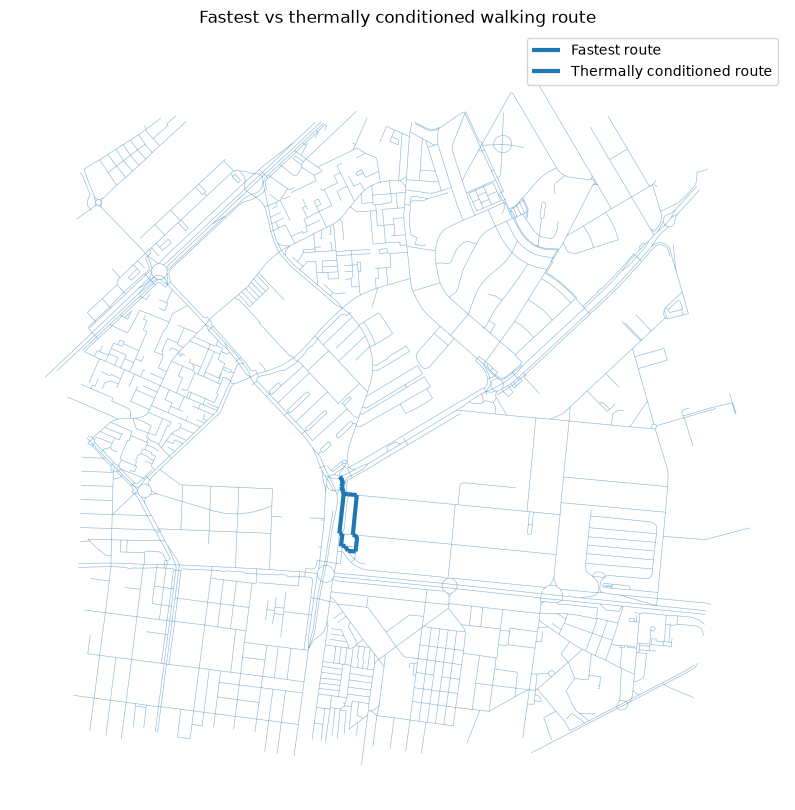

In [32]:
fig, ax = plt.subplots(
    figsize=(10, 10)
)

edges_gdf.plot(
    ax=ax,
    linewidth=0.4,
    alpha=0.3
)

fast_gdf.plot(
    ax=ax,
    linewidth=3,
    label="Fastest route"
)

thermal_gdf.plot(
    ax=ax,
    linewidth=3,
    label="Thermally conditioned route"
)

ax.legend()
ax.set_axis_off()

ax.set_title(
    "Fastest vs thermally conditioned walking route"
)

plt.show()

In [33]:
thermal_polygon = gpd.GeoSeries(
    [box(*edges_gdf.total_bounds)],
    crs=edges_gdf.crs
).to_crs(4326).iloc[0]

In [34]:
tags = {
    "highway": "bus_stop",
    "public_transport": [
        "platform",
        "stop_position"
    ]
}

stops = ox.features_from_polygon(
    thermal_polygon,
    tags=tags
)

In [35]:
stops = stops[
    stops.geometry.type.isin(
        ["Point", "Polygon", "MultiPolygon"]
    )
].copy()

In [36]:
stops = stops.to_crs(
    G_main.graph["crs"]
)

stops["geometry"] = (
    stops.geometry.centroid
)

In [37]:
stops = stops.drop_duplicates(
    subset="geometry"
)

print("Transit stops:", len(stops))

Transit stops: 291


In [38]:
stop_nodes = ox.distance.nearest_nodes(
    G_main,
    X=stops.geometry.x.values,
    Y=stops.geometry.y.values
)

stops["node"] = stop_nodes

In [39]:
stop_nodes = list(
    pd.unique(stops["node"])
)

print(
    "Unique stop nodes:",
    len(stop_nodes)
)

Unique stop nodes: 139


In [40]:
origin_nodes = rng.choice(
    list(G_main.nodes),
    size=min(
        50,
        G_main.number_of_nodes()
    ),
    replace=False
)

In [41]:
TIME_BUDGET = 10 * 60

In [42]:
access_results = []

for origin in origin_nodes:

    normal_costs = nx.single_source_dijkstra_path_length(
        G_main,
        origin,
        cutoff=TIME_BUDGET,
        weight="walk_time_s"
    )

    thermal_costs = nx.single_source_dijkstra_path_length(
        G_main,
        origin,
        cutoff=TIME_BUDGET,
        weight="thermal_cost_s"
    )

    normal_access = sum(
        node in normal_costs
        for node in stop_nodes
    )

    thermal_access = sum(
        node in thermal_costs
        for node in stop_nodes
    )

    access_results.append({
        "node": origin,
        "normal_access": normal_access,
        "thermal_access": thermal_access,
        "access_loss":
            normal_access
            - thermal_access
    })

In [43]:
access = pd.DataFrame(
    access_results
)

access.head()

,node,normal_access,thermal_access,access_loss
0,12705553216,27,16,11
1,10215553612,41,20,21
2,2448671721,31,20,11
3,5959692077,18,11,7
4,13031291689,31,13,18


In [44]:
access["access_loss_pct"] = np.where(
    access["normal_access"] > 0,
    100
    * access["access_loss"]
    / access["normal_access"],
    np.nan
)

In [45]:
access[
    [
        "normal_access",
        "thermal_access",
        "access_loss",
        "access_loss_pct"
    ]
].describe()

,normal_access,thermal_access,access_loss,access_loss_pct
count,50.000000,50.000000,50.000000,50.000000
mean,26.900000,13.280000,13.620000,49.601470
std,10.620062,5.473647,6.349964,13.628615
min,5.000000,0.000000,1.000000,10.000000
25%,18.000000,9.250000,8.000000,40.185185
50%,27.000000,13.000000,14.500000,51.136951
75%,35.000000,16.000000,18.000000,57.023810
max,45.000000,25.000000,25.000000,100.000000


In [46]:
access_gdf = nodes_gdf.loc[
    access["node"]
].copy()

access_gdf = access_gdf.join(
    access.set_index("node")
)

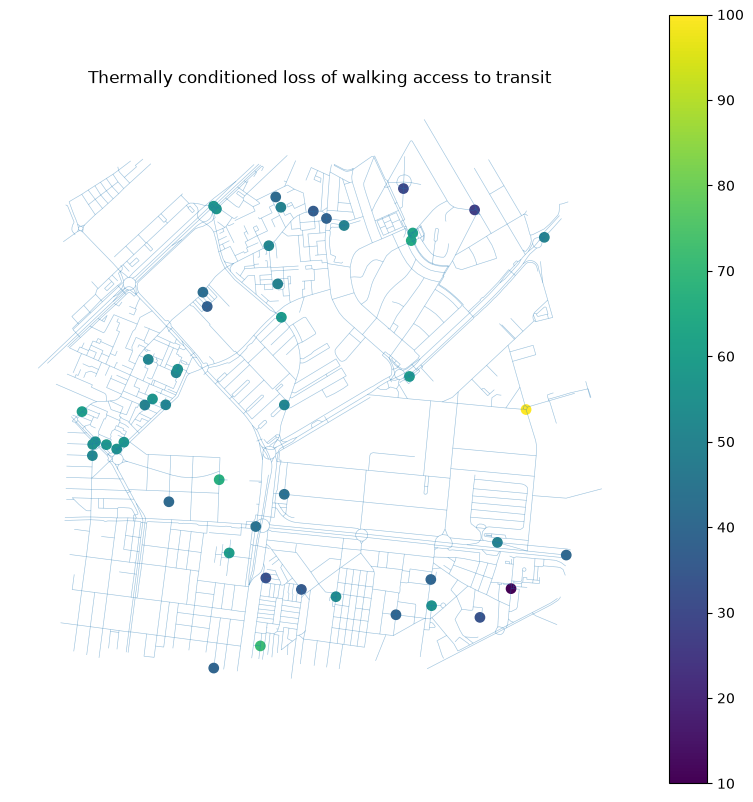

In [47]:
fig, ax = plt.subplots(
    figsize=(10, 10)
)

edges_gdf.plot(
    ax=ax,
    linewidth=0.4,
    alpha=0.25
)

access_gdf.plot(
    ax=ax,
    column="access_loss_pct",
    markersize=45,
    legend=True
)

ax.set_title(
    "Thermally conditioned loss of walking access to transit"
)

ax.set_axis_off()

plt.show()

In [48]:
print(
    f"Route changed: {changed_share:.1f}%"
)

print(
    route_results[
        "thermal_cost_reduction_pct"
    ].describe()
)

print(
    access[
        [
            "normal_access",
            "thermal_access",
            "access_loss_pct"
        ]
    ].describe()
)

Route changed: 31.0%
count    87.000000
mean      0.094600
std       0.339028
min       0.000000
25%       0.000000
50%       0.000000
75%       0.005119
max       2.924275
Name: thermal_cost_reduction_pct, dtype: float64
       normal_access  thermal_access  access_loss_pct
count      50.000000       50.000000        50.000000
mean       26.900000       13.280000        49.601470
std        10.620062        5.473647        13.628615
min         5.000000        0.000000        10.000000
25%        18.000000        9.250000        40.185185
50%        27.000000       13.000000        51.136951
75%        35.000000       16.000000        57.023810
max        45.000000       25.000000       100.000000


In [49]:
access["access_loss"] = (
    access["normal_access"]
    - access["thermal_access"]
)

access["access_loss_pct"] = (
    100
    * access["access_loss"]
    / access["normal_access"]
)

print(
    access[
        [
            "normal_access",
            "thermal_access",
            "access_loss",
            "access_loss_pct"
        ]
    ].describe()
)

       normal_access  thermal_access  access_loss  access_loss_pct
count      50.000000       50.000000    50.000000        50.000000
mean       26.900000       13.280000    13.620000        49.601470
std        10.620062        5.473647     6.349964        13.628615
min         5.000000        0.000000     1.000000        10.000000
25%        18.000000        9.250000     8.000000        40.185185
50%        27.000000       13.000000    14.500000        51.136951
75%        35.000000       16.000000    18.000000        57.023810
max        45.000000       25.000000    25.000000       100.000000


In [50]:
print(
    "Mean stops lost:",
    access["access_loss"].mean()
)

print(
    "Median stops lost:",
    access["access_loss"].median()
)

Mean stops lost: 13.62
Median stops lost: 14.5


In [55]:
_, edges_check = ox.graph_to_gdfs(G_main)

print(edges_check.columns.tolist())

['osmid', 'highway', 'name', 'oneway', 'reversed', 'length', 'geometry', 'midpoint', 'utci_max', 'walk_time_s', 'heat_excess', 'thermal_cost_s', 'cost_ratio', 'thermal_0.0', 'thermal_0.01', 'thermal_0.025', 'thermal_0.05', 'thermal_0.075', 'thermal_0.1', 'lanes', 'maxspeed', 'junction', 'access', 'service', 'bridge', 'tunnel', 'width']


In [61]:
for attr in [
    "walk_time_s",
    "heat_excess",
    "thermal_cost_s",
    "utci_max"
]:
    missing = sum(
        attr not in data
        for _, _, _, data in G_main.edges(
            keys=True,
            data=True
        )
    )

    print(attr, "missing:", missing)

walk_time_s missing: 0
heat_excess missing: 102
thermal_cost_s missing: 102
utci_max missing: 102


In [60]:
for lam in LAMBDA_VALUES:
    attr = f"thermal_{lam}"

    missing = sum(
        attr not in data
        for _, _, _, data in G_main.edges(keys=True, data=True)
    )

    print(attr, "missing:", missing)

thermal_0.0 missing: 4307
thermal_0.01 missing: 4307
thermal_0.025 missing: 4307
thermal_0.05 missing: 4307
thermal_0.075 missing: 4307
thermal_0.1 missing: 4307


In [62]:
print(
    "Total edges:",
    G_main.number_of_edges()
)

Total edges: 4494


In [63]:
attributes = [
    "walk_time_s",
    "utci_max",
    "heat_excess",
    "thermal_cost_s",
]

for attr in attributes:
    present = sum(
        attr in data
        for _, _, _, data in G_main.edges(keys=True, data=True)
    )

    missing = G_main.number_of_edges() - present

    print(
        f"{attr:20s} present: {present:4d} | missing: {missing:4d}"
    )

walk_time_s          present: 4494 | missing:    0
utci_max             present: 4392 | missing:  102
heat_excess          present: 4392 | missing:  102
thermal_cost_s       present: 4392 | missing:  102


In [64]:
_, edges_check = ox.graph_to_gdfs(G_main)

print(
    edges_check[
        [
            "walk_time_s",
            "utci_max",
            "heat_excess",
            "thermal_cost_s"
        ]
    ].isna().sum()
)

walk_time_s         0
utci_max          102
heat_excess       102
thermal_cost_s    102
dtype: int64


In [56]:
LAMBDA_VALUES = [
    0.00,
    0.01,
    0.025,
    0.05,
    0.075,
    0.10
]

sensitivity_results = []

for lam in LAMBDA_VALUES:

    weight = f"thermal_{lam}"

    for origin in origin_nodes:

        costs = nx.single_source_dijkstra_path_length(
            G_main,
            origin,
            cutoff=TIME_BUDGET,
            weight=weight
        )

        reachable = sum(
            node in costs
            for node in stop_nodes
        )

        sensitivity_results.append({
            "lambda": lam,
            "origin": origin,
            "reachable_stops": reachable
        })

sensitivity = pd.DataFrame(sensitivity_results)

In [65]:
nodes_all, edges_all = ox.graph_to_gdfs(G_main)

edges_valid = edges_all[
    edges_all["walk_time_s"].notna()
    & edges_all["utci_max"].notna()
    & edges_all["heat_excess"].notna()
].copy()

print("Original edges:", len(edges_all))
print("Valid thermal edges:", len(edges_valid))
print(
    "Retained:",
    100 * len(edges_valid) / len(edges_all),
    "%"
)

Original edges: 4494
Valid thermal edges: 4392
Retained: 97.73030707610147 %


In [66]:
valid_node_ids = (
    set(edges_valid.index.get_level_values("u"))
    | set(edges_valid.index.get_level_values("v"))
)

nodes_valid = nodes_all.loc[
    nodes_all.index.intersection(valid_node_ids)
].copy()

# Important for OSMnx graph reconstruction
nodes_valid["x"] = nodes_valid.geometry.x
nodes_valid["y"] = nodes_valid.geometry.y

G_valid = ox.graph_from_gdfs(
    nodes_valid,
    edges_valid,
    graph_attrs={"crs": G_main.graph["crs"]}
)

In [67]:
largest_component = max(
    nx.strongly_connected_components(G_valid),
    key=len
)

G_main = G_valid.subgraph(
    largest_component
).copy()

print("Final nodes:", G_main.number_of_nodes())
print("Final edges:", G_main.number_of_edges())

Final nodes: 1523
Final edges: 4392


In [68]:
LAMBDA_VALUES = [
    0.00,
    0.01,
    0.025,
    0.05,
    0.075,
    0.10
]

for _, _, _, data in G_main.edges(
    keys=True,
    data=True
):
    walk_time = float(data["walk_time_s"])
    heat_excess = float(data["heat_excess"])

    for lam in LAMBDA_VALUES:
        data[f"thermal_{lam}"] = (
            walk_time
            * (1 + lam * heat_excess)
        )

In [69]:
for lam in LAMBDA_VALUES:
    attr = f"thermal_{lam}"

    missing = sum(
        attr not in data
        for _, _, _, data
        in G_main.edges(keys=True, data=True)
    )

    print(attr, "missing:", missing)

thermal_0.0 missing: 0
thermal_0.01 missing: 0
thermal_0.025 missing: 0
thermal_0.05 missing: 0
thermal_0.075 missing: 0
thermal_0.1 missing: 0


In [70]:
max_diff = max(
    abs(
        float(data["thermal_0.0"])
        - float(data["walk_time_s"])
    )
    for _, _, _, data
    in G_main.edges(keys=True, data=True)
)

print("Maximum λ=0 difference:", max_diff)

Maximum λ=0 difference: 0.0


In [71]:
origin_nodes = [
    node for node in origin_nodes
    if node in G_main
]

stop_nodes = [
    node for node in stop_nodes
    if node in G_main
]

print("Origins retained:", len(origin_nodes))
print("Stops retained:", len(stop_nodes))
print("Unique stops:", len(set(stop_nodes)))

Origins retained: 49
Stops retained: 129
Unique stops: 129


In [72]:
sensitivity_results = []

for lam in LAMBDA_VALUES:
    weight = f"thermal_{lam}"

    for origin in origin_nodes:
        costs = nx.single_source_dijkstra_path_length(
            G_main,
            origin,
            cutoff=TIME_BUDGET,
            weight=weight
        )

        reachable = sum(
            stop in costs
            for stop in stop_nodes
        )

        sensitivity_results.append({
            "lambda": lam,
            "origin": origin,
            "reachable_stops": reachable
        })

sensitivity = pd.DataFrame(sensitivity_results)

In [73]:
sensitivity_summary = (
    sensitivity
    .groupby("lambda")["reachable_stops"]
    .agg(
        mean="mean",
        median="median",
        std="std",
        min="min",
        max="max"
    )
    .reset_index()
)

baseline_mean = (
    sensitivity_summary
    .loc[
        sensitivity_summary["lambda"] == 0.0,
        "mean"
    ]
    .iloc[0]
)

sensitivity_summary["mean_access_loss_pct"] = (
    100
    * (
        baseline_mean
        - sensitivity_summary["mean"]
    )
    / baseline_mean
)

sensitivity_summary

,lambda,mean,median,std,min,max,mean_access_loss_pct
0,0.000,26.326531,27.0,10.859688,5,45,0.000000
1,0.010,21.979592,22.0,9.967635,4,41,16.511628
2,0.025,17.285714,17.0,7.876653,0,36,34.341085
3,0.050,12.673469,13.0,5.821611,0,25,51.860465
4,0.075,9.489796,10.0,4.505194,0,20,63.953488
5,0.100,7.428571,7.0,3.937004,0,17,71.782946


In [74]:
sensitivity_summary[
    sensitivity_summary["lambda"].isin(
        [0.0, 0.05]
    )
]

,lambda,mean,median,std,min,max,mean_access_loss_pct
0,0.00,26.326531,27.0,10.859688,5,45,0.000000
3,0.05,12.673469,13.0,5.821611,0,25,51.860465


In [75]:
baseline = (
    sensitivity[
        sensitivity["lambda"] == 0.0
    ][["origin", "reachable_stops"]]
    .rename(
        columns={
            "reachable_stops": "normal_access"
        }
    )
)

heat_005 = (
    sensitivity[
        sensitivity["lambda"] == 0.05
    ][["origin", "reachable_stops"]]
    .rename(
        columns={
            "reachable_stops": "thermal_access"
        }
    )
)

access_clean = baseline.merge(
    heat_005,
    on="origin"
)

access_clean["access_loss"] = (
    access_clean["normal_access"]
    - access_clean["thermal_access"]
)

access_clean["access_loss_pct"] = (
    100
    * access_clean["access_loss"]
    / access_clean["normal_access"]
)

access_clean.describe()

,origin,normal_access,thermal_access,access_loss,access_loss_pct
count,4.900000e+01,49.000000,49.000000,49.000000,49.000000
mean,5.530676e+09,26.326531,12.673469,13.653061,51.571989
std,5.059429e+09,10.859688,5.821611,6.296663,13.384802
min,4.055571e+08,5.000000,0.000000,2.000000,22.222222
25%,8.631925e+08,18.000000,8.000000,8.000000,43.243243
50%,2.448672e+09,27.000000,13.000000,14.000000,51.851852
75%,1.074401e+10,34.000000,16.000000,18.000000,58.064516
max,1.306318e+10,45.000000,25.000000,25.000000,100.000000


In [76]:
rng = np.random.default_rng(42)

nodes_array = np.array(list(G_main.nodes))

pairs = []

while len(pairs) < 100:
    origin, destination = rng.choice(
        nodes_array,
        size=2,
        replace=False
    )

    pairs.append((origin, destination))

In [77]:
results = []

for origin, destination in pairs:
    try:
        result, _, _ = compare_routes(
            G_main,
            origin,
            destination
        )

        results.append(result)

    except nx.NetworkXNoPath:
        pass

route_results_clean = pd.DataFrame(results)

changed_share_clean = (
    (~route_results_clean["same_route"]).mean()
    * 100
)

print(
    f"Route changed: "
    f"{changed_share_clean:.1f}%"
)

print(
    route_results_clean[
        "thermal_cost_reduction_pct"
    ].describe()
)

Route changed: 31.0%
count    100.000000
mean       0.109512
std        0.315804
min        0.000000
25%        0.000000
50%        0.000000
75%        0.060924
max        2.317816
Name: thermal_cost_reduction_pct, dtype: float64


In [78]:
OUTPUTS = PROJECT_ROOT / "outputs" / "accessibility"
OUTPUTS.mkdir(
    parents=True,
    exist_ok=True
)

route_results_clean.to_csv(
    OUTPUTS / "route_results_lambda_005.csv",
    index=False
)

sensitivity_summary.to_csv(
    OUTPUTS / "accessibility_sensitivity.csv",
    index=False
)

access_clean.to_csv(
    OUTPUTS / "origin_accessibility_lambda_005.csv",
    index=False
)